# Yearly ISOP and MTERP emissions: two runs per panel
Emissions **received by the atmosphere** in each run (`SFISOP`, `SFMTERP` = MEGAN or prescribed, plus biomass burning; CAM h0). They are not the forcing files (those are in `plot_bvoc_emissions.ipynb`).

- **One panel per contrast A − B**, legend order A then B. Legend: mean over the **years both runs share**, then Δ = A − B in Tg/yr and as % of B.
- **Colours (user 2026-11-08):** LCC runs, and fixed-BVOC runs with *lcc* emissions: **red** (FUT) / **navy** (PD). CTRL runs, and fixed-BVOC runs with *ctrl* emissions: **orange** (FUT) / **teal** (PD). Fixed-BVOC runs are coloured by their emission source and drawn **dashed**; interactive runs are solid. If both runs of a panel use the same emission source (section 3), they are coloured by their own land cover and climate instead.
- **Units:** Tg(species)/yr, area-integrated over the LCC-modified cells (1161 cells, 46–82°N, `diagnostics/lcc-modified-cells/modified_cells.nc`).
- **Same vertical scale in every panel** (ISOP and MTERP figures too), so heights can be compared across panels.
- **Years:** 2001–2014, with year 2000 dropped as spin-up. Only complete calendar years are used.
- **Input:** `data/processed-data/postprocessing/<ALIAS>_atm_BVOC_2001-2014.nc` where it exists, otherwise the raw h0 files listed in `RAW` (currently `LCC_FUT_fBVOClccFUT`, 24g, still running, so its line is shorter).
- Prescribed runs read a climatology that repeats every year, so their lines are flat apart from biomass burning.

| Section | Contrasts |
|---|---|
| 1. Total and background | LCC_FUT − CTRL_PD; LCC_PD − CTRL_PD; LCC_FUT − CTRL_FUT; CTRL_FUT − CTRL_PD (PV); LCC_FUT − LCC_PD (FV) |
| 2. BVOC-related | LCC_PD_fBVOC[lccPD − ctrlPD]; LCC_FUT_fBVOC[lccFUT − ctrlFUT], [lccFUT − lccPD], [lccFUT − ctrlPD], [ctrlFUT − ctrlPD], [lccPD − ctrlPD] |
| 3. Non-BVOC | [LCC_PD − CTRL_PD]_fBVOCctrlPD; [LCC_FUT − CTRL_FUT]_fBVOCctrlFUT; [LCC_FUT − LCC_PD]_fBVOCctrlPD; [LCC_FUT − CTRL_PD]_fBVOCctrlPD |
| 4. Artefacts (interactive − prescribed own emissions) | art_LCC_PD, art_LCC_FUT, art_CTRL_PD, art_CTRL_FUT |

Artefacts (user list 2026-11-08 22:07): art_LCC_PD = LCC_PD − LCC_PD_fBVOCctrlPD, art_LCC_FUT = LCC_FUT − LCC_FUT_fBVOCctrlFUT, art_CTRL_PD = CTRL_PD − CTRL_PD_fBVOCctrlPD, art_CTRL_FUT = CTRL_FUT − CTRL_FUT_fBVOCctrlFUT.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

REPO = Path("/cluster/home/adelez/BOREAL-FOREST-EXPANSION")
PROC = REPO / "data/processed-data/postprocessing"
MASK_FILE = REPO / "diagnostics/lcc-modified-cells/modified_cells.nc"
# Runs without a processed BVOC file yet: raw CAM h0 (keep up to date with run versions, CLAUDE.md).
RAW = {"LCC_FUT_fBVOClccFUT": Path("/cluster/work/users/adelez/archive/"
                                  "NF2100ssp585norbc_tropstratchem_nudg_lcc_fBVOClccFUT_f19_f19-20261106/atm/hist")}
START, END = 2001, 2014
SPECIES = {"SFISOP": "ISOP", "SFMTERP": "MTERP"}
# project palette; LCC family red/navy, CTRL family orange/teal; FUT warm, PD cool (user 2026-11-08)
COLOR = {("lcc", "FUT"): "#BC423E", ("lcc", "PD"): "#2C3990", ("ctrl", "FUT"): "#DE7A3A", ("ctrl", "PD"): "#5D9A92"}

def own_key(alias):
    """(land, climate) of the run itself: LCC_FUT_fBVOCctrlPD -> ('lcc', 'FUT')."""
    land, clim = alias.split("_")[:2]
    return land.lower(), clim

def source_key(alias):
    """Emission source: fixed BVOC -> its source (fBVOCctrlPD -> ('ctrl', 'PD')); interactive -> the run itself."""
    if "_fBVOC" in alias:
        src = alias.split("_fBVOC")[1]
        land = "lcc" if src.startswith("lcc") else "ctrl"
        return land, src[len(land):]
    return own_key(alias)

def line_colors(a, b):
    ka, kb = source_key(a), source_key(b)
    if ka == kb and "_fBVOC" in a and "_fBVOC" in b:      # same prescribed file: fall back to the runs themselves
        ka, kb = own_key(a), own_key(b)
    return COLOR[ka], COLOR[kb]

# section -> list of (panel title, A, B); B or A = None if the run does not exist
SECTIONS = {
    "1. Total and background": [
        ("LCC + CC combined\nLCC_FUT − CTRL_PD", "LCC_FUT", "CTRL_PD"),
        ("LCC total, PD climate\nLCC_PD − CTRL_PD", "LCC_PD", "CTRL_PD"),
        ("LCC total, FUT climate\nLCC_FUT − CTRL_FUT", "LCC_FUT", "CTRL_FUT"),
        ("Background CC, current veg. (PV)\nCTRL_FUT − CTRL_PD", "CTRL_FUT", "CTRL_PD"),
        ("Background CC, future veg. (FV)\nLCC_FUT − LCC_PD", "LCC_FUT", "LCC_PD"),
    ],
    "2. BVOC-related": [
        ("LCC_PD_fBVOC [lccPD − ctrlPD]\nemission change from LCC, PD", "LCC_PD_fBVOClccPD", "LCC_PD_fBVOCctrlPD"),
        ("LCC_FUT_fBVOC [lccFUT − ctrlFUT]\nemission change from LCC, FUT", "LCC_FUT_fBVOClccFUT", "LCC_FUT_fBVOCctrlFUT"),
        ("LCC_FUT_fBVOC [lccFUT − lccPD]\nemission change from CC, LCC veg.", "LCC_FUT_fBVOClccFUT", "LCC_FUT_fBVOClccPD"),
        ("LCC_FUT_fBVOC [lccFUT − ctrlPD]\nemission change from LCC + CC", "LCC_FUT_fBVOClccFUT", "LCC_FUT_fBVOCctrlPD"),
        ("LCC_FUT_fBVOC [ctrlFUT − ctrlPD]\nemission change from CC, current veg.", "LCC_FUT_fBVOCctrlFUT", "LCC_FUT_fBVOCctrlPD"),
        ("LCC_FUT_fBVOC [lccPD − ctrlPD]\n(not physical) LCC emissions, FUT", "LCC_FUT_fBVOClccPD", "LCC_FUT_fBVOCctrlPD"),
    ],
    "3. Non-BVOC": [
        ("[LCC_PD − CTRL_PD]_fBVOCctrlPD", "LCC_PD_fBVOCctrlPD", "CTRL_PD_fBVOCctrlPD"),
        ("[LCC_FUT − CTRL_FUT]_fBVOCctrlFUT", "LCC_FUT_fBVOCctrlFUT", "CTRL_FUT_fBVOCctrlFUT"),
        ("[LCC_FUT − LCC_PD]_fBVOCctrlPD", "LCC_FUT_fBVOCctrlPD", "LCC_PD_fBVOCctrlPD"),
        ("[LCC_FUT − CTRL_PD]_fBVOCctrlPD", "LCC_FUT_fBVOCctrlPD", "CTRL_PD_fBVOCctrlPD"),
    ],
    "4. Artefacts (interactive − prescribed)": [
        ("art_LCC_PD\nLCC_PD − LCC_PD_fBVOCctrlPD", "LCC_PD", "LCC_PD_fBVOCctrlPD"),
        ("art_LCC_FUT\nLCC_FUT − LCC_FUT_fBVOCctrlFUT", "LCC_FUT", "LCC_FUT_fBVOCctrlFUT"),
        ("art_CTRL_PD\nCTRL_PD − CTRL_PD_fBVOCctrlPD", "CTRL_PD", "CTRL_PD_fBVOCctrlPD"),
        ("art_CTRL_FUT\nCTRL_FUT − CTRL_FUT_fBVOCctrlFUT", "CTRL_FUT", "CTRL_FUT_fBVOCctrlFUT"),
    ],
}
ALIASES = sorted({r for rows in SECTIONS.values() for _, a, b in rows for r in (a, b)})
REGION = "modified"
print(len(ALIASES), "runs:", ", ".join(ALIASES))

12 runs: CTRL_FUT, CTRL_FUT_fBVOCctrlFUT, CTRL_PD, CTRL_PD_fBVOCctrlPD, LCC_FUT, LCC_FUT_fBVOCctrlFUT, LCC_FUT_fBVOCctrlPD, LCC_FUT_fBVOClccFUT, LCC_FUT_fBVOClccPD, LCC_PD, LCC_PD_fBVOCctrlPD, LCC_PD_fBVOClccPD


## 1. Yearly totals per run and region
Monthly flux (kg m⁻² s⁻¹) × cell area × seconds in the month (noleap), summed over each calendar year. Cell areas come from `gw` (Gaussian weights) and are scaled so the globe = 4πR², R = 6.371 × 10⁶ m. The grid of every run is checked against the mask grid; a mismatch stops the notebook.

In [2]:
with xr.open_dataset(MASK_FILE) as ds:
    mask = ds["modified"].load().astype(bool)

def open_run(alias):
    """SFISOP/SFMTERP monthly fields with a 'year' and 'days' coordinate."""
    proc = PROC / f"{alias}_atm_BVOC_{START}-{END}.nc"
    if proc.exists():
        source = proc.name
        ds = xr.open_dataset(proc)
        bounds = ds["time_bnds"].values
        ds = ds[[*SPECIES, "gw"]]
    else:
        files = sorted(RAW[alias].glob("*.cam.h0.*.nc"))
        ds = xr.open_mfdataset(files, data_vars="minimal", coords="minimal", compat="override",
                               combine="by_coords")
        bounds = ds["time_bnds"].values
        ds = ds[[*SPECIES, "gw"]]
        source = f"raw h0 ({len(files)} files in {RAW[alias].parent.parent.name})"
    t0 = np.array([b[0] for b in bounds]); t1 = np.array([b[1] for b in bounds])
    if type(t0[0]).__name__ != "DatetimeNoLeap":
        raise ValueError(f"{alias}: calendar {type(t0[0]).__name__}, expected noleap")
    days = np.array([(b - a).days for a, b in zip(t0, t1)], float)
    years = np.array([a.year for a in t0])
    ds = ds.assign_coords(year=("time", years), days=("time", days))
    for s in SPECIES:
        if ds[s].attrs.get("units") != "kg/m2/s":
            raise ValueError(f"{alias} {s}: units {ds[s].attrs.get('units')}")
    return ds, source

R = 6.371e6
annual, sources = {}, {}
for alias in ALIASES:
    ds, sources[alias] = open_run(alias)
    for name, a, b in (("lat", mask.lat.values, ds.lat.values), ("lon", mask.lon.values % 360, ds.lon.values % 360)):
        if a.shape != b.shape or np.abs(a - b).max() > 1e-5:
            raise ValueError(f"{alias}: mask and model {name} differ")
    gw = ds["gw"].isel(time=0) if "time" in ds["gw"].dims else ds["gw"]
    area = (gw / float(gw.sum()) / ds.sizes["lon"] * 4 * np.pi * R**2) * xr.ones_like(ds.lon)   # m2
    regions = {REGION: area.where(mask.assign_coords(lat=ds.lat, lon=ds.lon), 0)}
    rows = []
    for s in SPECIES:
        kg_per_month = ds[s] * ds["days"] * 86400                       # kg m-2 per month
        for r, w in regions.items():
            monthly = (kg_per_month * w).sum(("lat", "lon")).load()
            g = monthly.groupby("year")
            n = g.count().to_series()
            tot = g.sum().to_series() / 1e9                              # Tg/yr
            full = n.index[(n == 12) & (n.index >= START) & (n.index <= END)]
            rows.append(pd.DataFrame({"alias": alias, "species": SPECIES[s], "region": r,
                                      "year": full, "Tg_per_yr": tot.loc[full].values}))
    annual[alias] = pd.concat(rows)
    yrs = annual[alias].year.unique()
    print(f"{alias:24s} {yrs.min()}–{yrs.max()} ({len(yrs)} yr)  from {sources[alias]}")
annual = pd.concat(annual.values(), ignore_index=True)

CTRL_FUT                 2001–2014 (14 yr)  from CTRL_FUT_atm_BVOC_2001-2014.nc
CTRL_FUT_fBVOCctrlFUT    2001–2014 (14 yr)  from CTRL_FUT_fBVOCctrlFUT_atm_BVOC_2001-2014.nc
CTRL_PD                  2001–2014 (14 yr)  from CTRL_PD_atm_BVOC_2001-2014.nc
CTRL_PD_fBVOCctrlPD      2001–2014 (14 yr)  from CTRL_PD_fBVOCctrlPD_atm_BVOC_2001-2014.nc
LCC_FUT                  2001–2014 (14 yr)  from LCC_FUT_atm_BVOC_2001-2014.nc
LCC_FUT_fBVOCctrlFUT     2001–2014 (14 yr)  from LCC_FUT_fBVOCctrlFUT_atm_BVOC_2001-2014.nc
LCC_FUT_fBVOCctrlPD      2001–2014 (14 yr)  from LCC_FUT_fBVOCctrlPD_atm_BVOC_2001-2014.nc
LCC_FUT_fBVOClccFUT      2001–2009 (9 yr)  from raw h0 (120 files in NF2100ssp585norbc_tropstratchem_nudg_lcc_fBVOClccFUT_f19_f19-20261106)
LCC_FUT_fBVOClccPD       2001–2014 (14 yr)  from LCC_FUT_fBVOClccPD_atm_BVOC_2001-2014.nc
LCC_PD                   2001–2014 (14 yr)  from LCC_PD_atm_BVOC_2001-2014.nc
LCC_PD_fBVOCctrlPD       2001–2014 (14 yr)  from LCC_PD_fBVOCctrlPD_atm_BVOC_2001-2014.

## 2. Means per run over its own years (Tg/yr)
Check table: one row per run, mean over the years that run has. Δ and % for each contrast are in section 4.

In [3]:
means = annual.groupby(["alias", "species", "region"]).Tg_per_yr.mean().unstack(["species", "region"])
yrs = annual.groupby("alias").year.agg(lambda y: f"{y.min()}–{y.max()}")
means.insert(0, ("years", ""), yrs)
with pd.option_context("display.float_format", "{:.4g}".format, "display.width", 200):
    display(means)

species,years,ISOP,MTERP
region,,modified,modified
alias,,,
CTRL_FUT,2001–2014,12.49,22.6
CTRL_FUT_fBVOCctrlFUT,2001–2014,12.48,22.59
CTRL_PD,2001–2014,4.126,4.976
CTRL_PD_fBVOCctrlPD,2001–2014,4.124,4.974
LCC_FUT,2001–2014,12.85,22.48
LCC_FUT_fBVOCctrlFUT,2001–2014,12.48,22.59
LCC_FUT_fBVOCctrlPD,2001–2014,4.124,4.974
LCC_FUT_fBVOClccFUT,2001–2009,12.85,22.47


## 3. Time series, one figure per species (LCC-modified cells)
Rows = sections 1–4. Solid = interactive emissions, dashed = fixed BVOC; thin dotted lines = means over the shared years. One y-range for all panels of both figures.

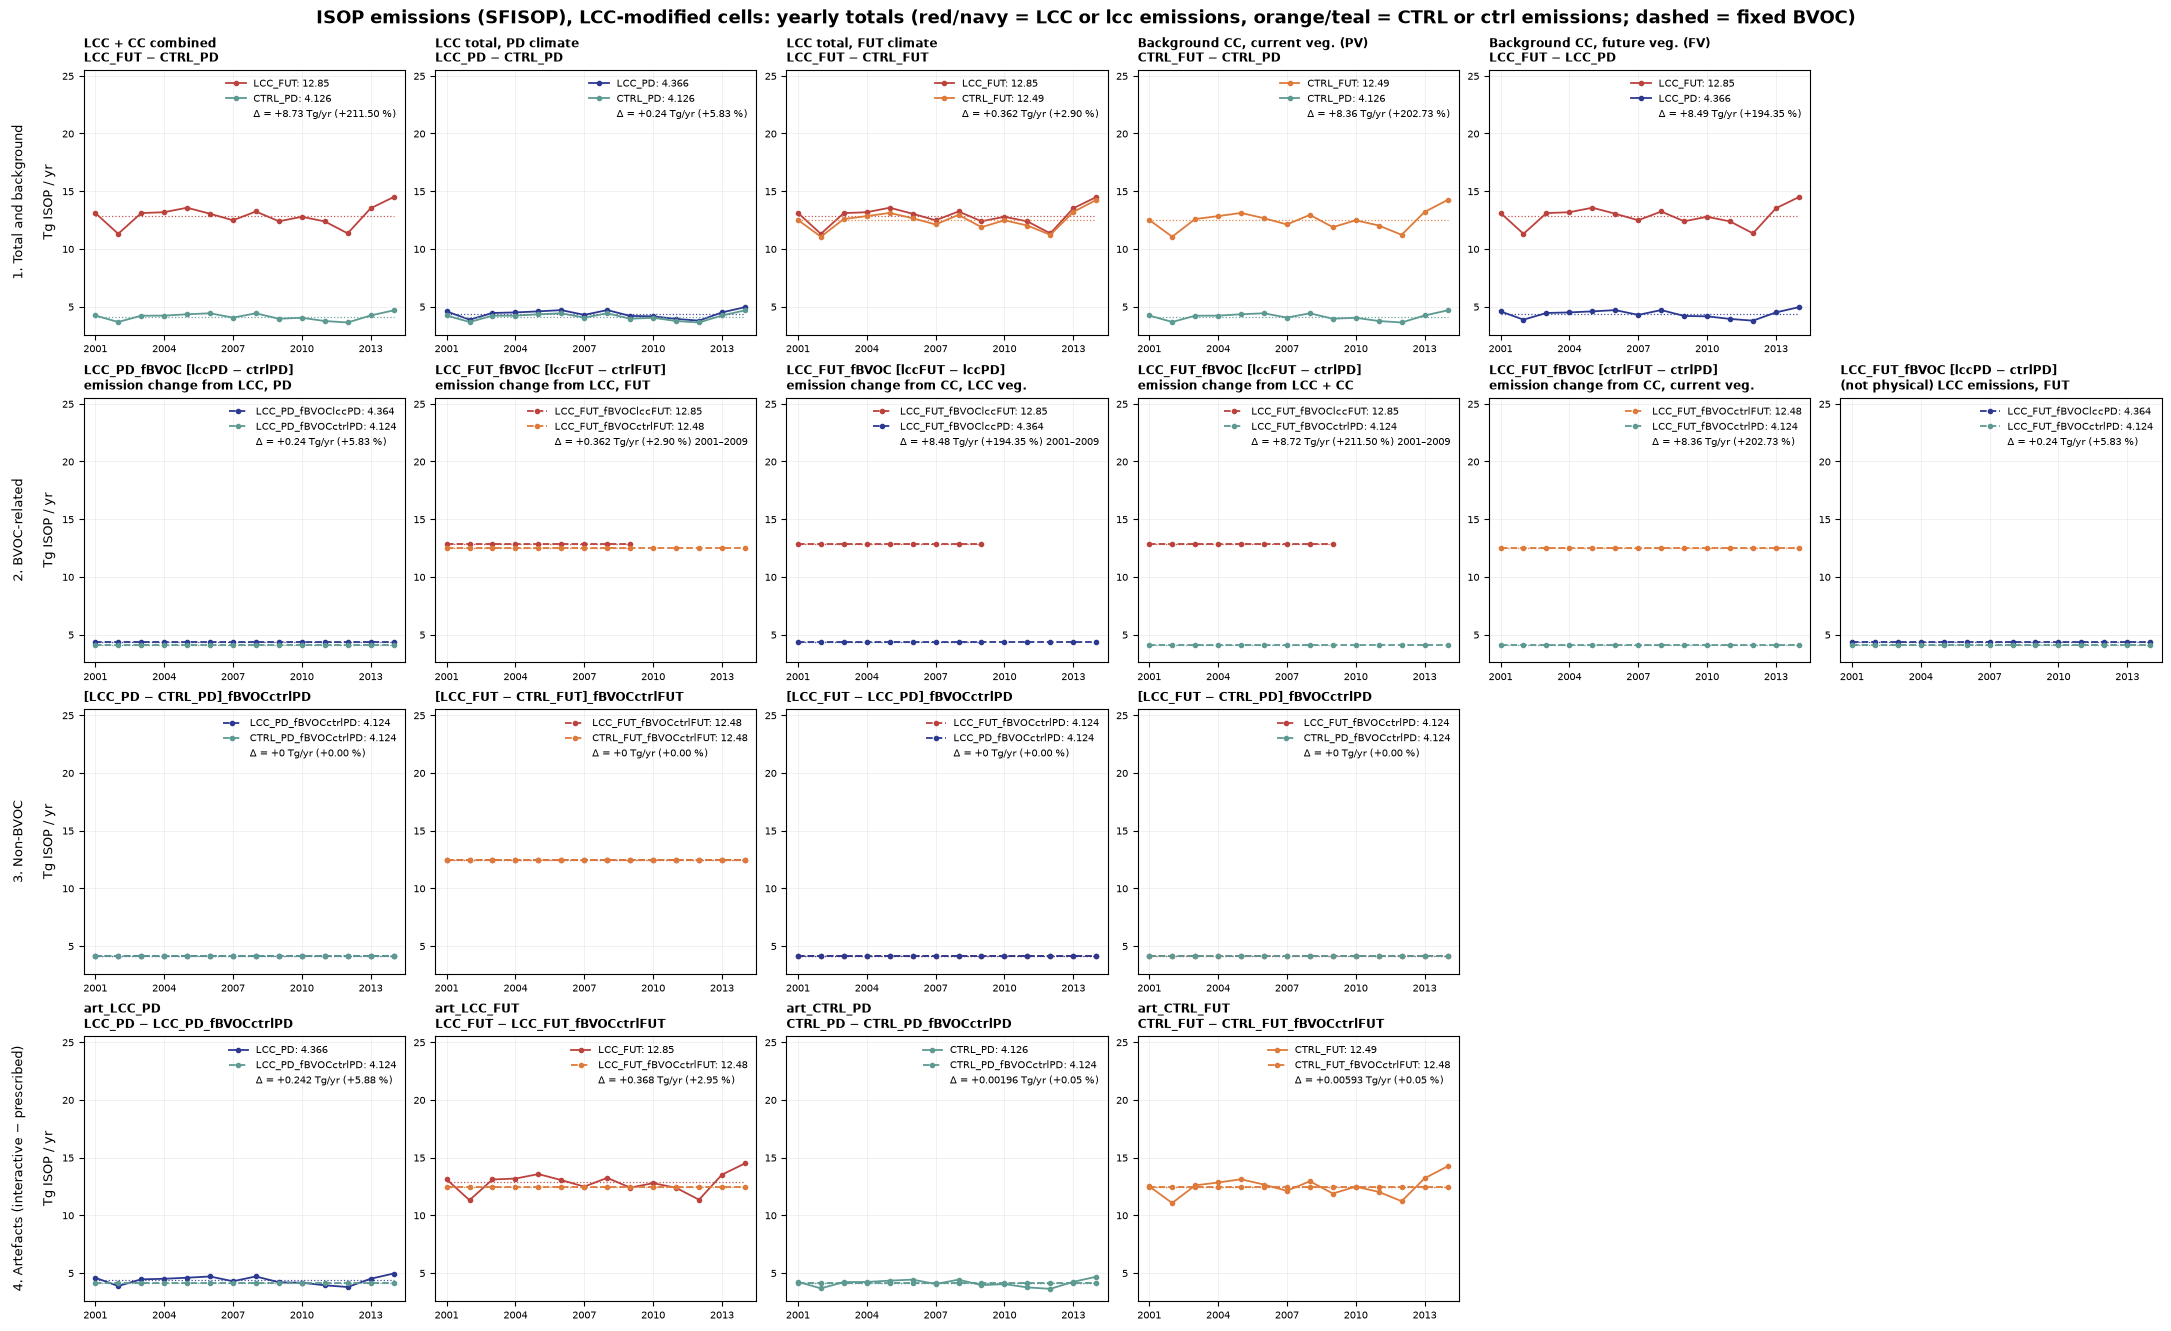

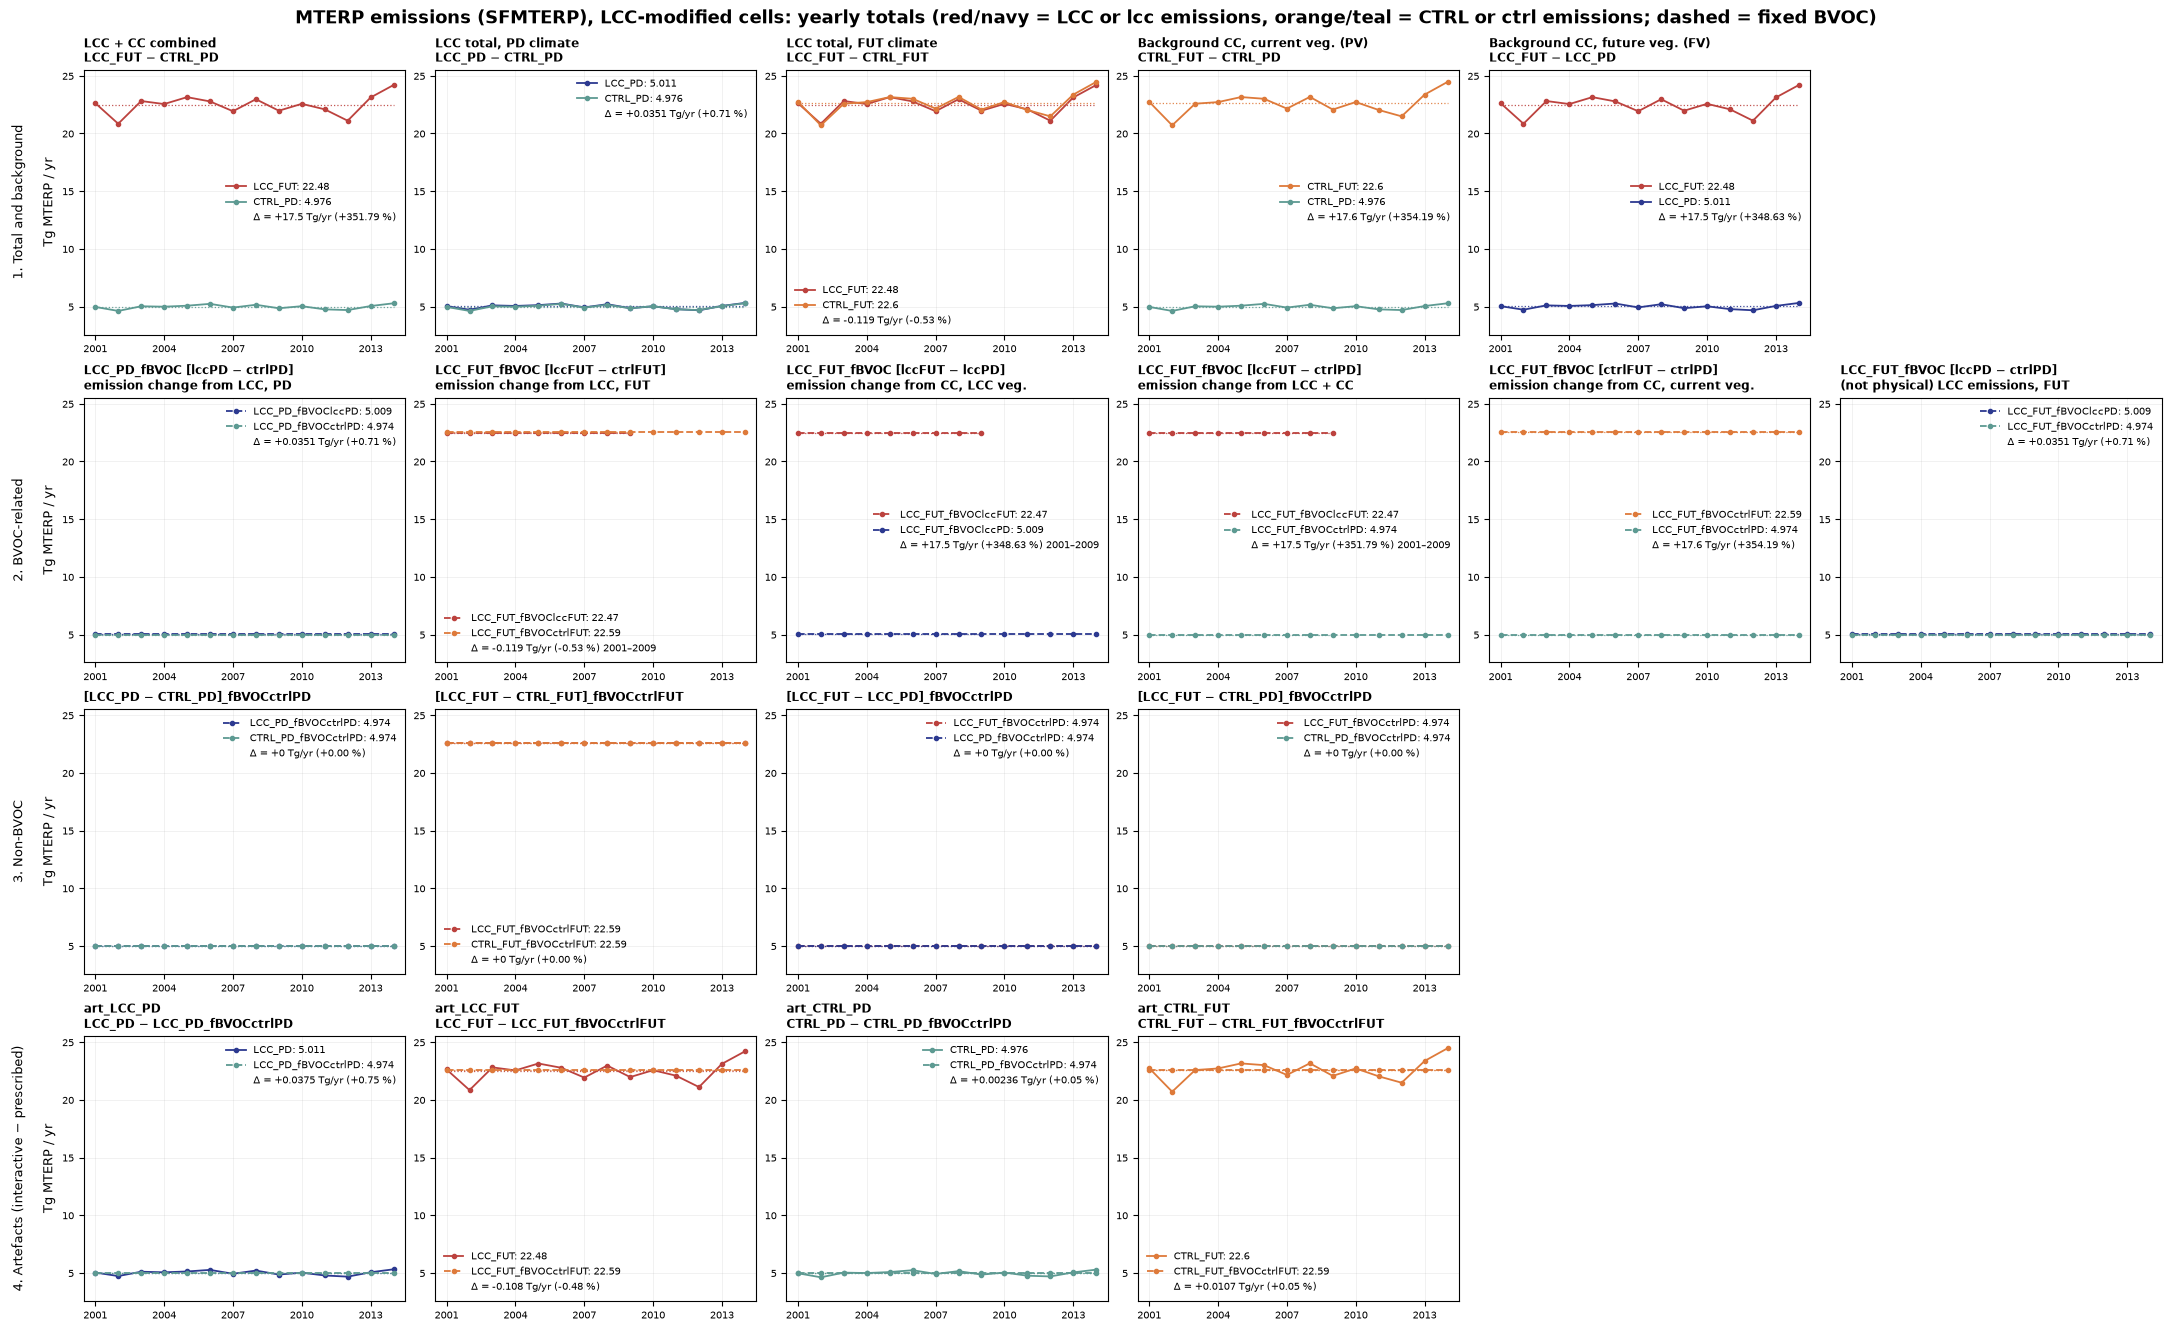

In [4]:
def series(alias, species, region):
    d = annual[(annual.alias == alias) & (annual.species == species) & (annual.region == region)]
    return d.set_index("year").Tg_per_yr.sort_index()

def contrast_stats(a, b, species, region):
    sa, sb = series(a, species, region), series(b, species, region)
    common = sa.index.intersection(sb.index)
    ma, mb = sa.loc[common].mean(), sb.loc[common].mean()
    return common, ma, mb, ma - mb, 100 * (ma - mb) / mb

REGION_LABEL = {REGION: "LCC-modified cells"}
lo, hi = annual.Tg_per_yr.min(), annual.Tg_per_yr.max()
YLIM = (max(0, lo - 0.05 * (hi - lo)), hi + 0.05 * (hi - lo))   # shared by every panel
NCOL = max(len(v) for v in SECTIONS.values())

def plot_species_region(species, region):
    fig, axes = plt.subplots(len(SECTIONS), NCOL, figsize=(3.6 * NCOL, 3.3 * len(SECTIONS)),
                             constrained_layout=True, squeeze=False)
    for row, (section, panels) in zip(axes, SECTIONS.items()):
        for ax in row[len(panels):]:
            ax.axis("off")
        for j, (ax, (title, a, b)) in enumerate(zip(row, panels)):
            ax.set_title(title, fontsize=8.5, fontweight="bold", loc="left")
            if j == 0:
                ax.set_ylabel(f"{section}\n\nTg {species} / yr", fontsize=9)
            ax.grid(alpha=0.25, lw=0.5)
            ax.tick_params(labelsize=7.5)
            ax.set_xticks(range(START, END + 1, 3))
            ax.set_ylim(YLIM)
            common, ma, mb, d, pct = contrast_stats(a, b, species, region)
            for alias, m, color in zip((a, b), (ma, mb), line_colors(a, b)):
                s = series(alias, species, region)
                ax.plot(s.index, s.values, marker="o", ms=3, lw=1.3, color=color, ls="--" if "_fBVOC" in alias else "-",
                        label=f"{alias}: {m:.4g}")
                ax.hlines(m, common.min(), common.max(), colors=color, lw=0.9, ls=":", alpha=0.9)
            span = f"{common.min()}–{common.max()}" if len(common) < END - START + 1 else ""
            ax.plot([], [], " ", label=f"Δ = {d:+.3g} Tg/yr ({pct:+.2f} %) {span}".rstrip())
            ax.legend(fontsize=7, loc="best", frameon=False)
            ax.set_xlim(START - 0.5, END + 0.5)
    fig.suptitle(f"{species} emissions (SF{species}), {REGION_LABEL[region]}: yearly totals (red/navy = LCC or lcc emissions, orange/teal = CTRL or ctrl emissions; dashed = fixed BVOC)",
                 fontsize=13, fontweight="bold")
    plt.show(); plt.close(fig)

for species in SPECIES.values():
    plot_species_region(species, REGION)

## 4. Contrast table (LCC-modified cells; Tg/yr, over the years both runs share)

In [5]:
rows = []
for section, panels in SECTIONS.items():
    for title, a, b in panels:
        for species in SPECIES.values():
            for region in REGION_LABEL:
                common, ma, mb, d, pct = contrast_stats(a, b, species, region)
                row = {"section": section, "contrast": title.replace("\n", " | "), "species": species, "region": region,
                       "years": f"{common.min()}–{common.max()}", "A": ma, "B": mb, "delta": d, "pct": pct}
                rows.append(row)
table = pd.DataFrame(rows)
wide = table.pivot_table(index=["section", "contrast"], columns=["species", "region"], values=["delta", "pct"], sort=False)
with pd.option_context("display.float_format", "{:+.3g}".format, "display.width", 250, "display.max_colwidth", 60):
    display(wide)

delta               pct         
species                                                                                                  ISOP    MTERP     ISOP    MTERP
region                                                                                               modified modified modified modified
section                                 contrast                                                                                        
1. Total and background                 LCC + CC combined | LCC_FUT − CTRL_PD                           +8.73    +17.5     +211     +352
                                        LCC total, PD climate | LCC_PD − CTRL_PD                        +0.24  +0.0351    +5.83   +0.706
                                        LCC total, FUT climate | LCC_FUT − CTRL_FUT                    +0.362   -0.119     +2.9   -0.527
                                        Background CC, current veg. (PV) | CTRL_FUT − CTRL_PD           +8.36    +17.6     +203     +354
                                        Background CC, future veg. (FV) | LCC_FUT − LCC_PD              +8.49    +17.5     +194     +349
2. BVOC-related                         LCC_PD_fBVOC [lccPD − ctrlPD] | emission change from LCC, PD    +0.24  +0.0351    +5.83   +0.706
                                        LCC_FUT_fBVOC [lccFUT − ctrlFUT] | emission change from L...   +0.362   -0.119     +2.9   -0.527
                                        LCC_FUT_fBVOC [lccFUT − lccPD] | emission change from CC,...    +8.48    +17.5     +194     +349
                                        LCC_FUT_fBVOC [lccFUT − ctrlPD] | emission change from LC...    +8.72    +17.5     +211     +352
                                        LCC_FUT_fBVOC [ctrlFUT − ctrlPD] | emission change from C...    +8.36    +17.6     +203     +354
                                        LCC_FUT_fBVOC [lccPD − ctrlPD] | (not physical) LCC emiss...    +0.24  +0.0351    +5.83   +0.706
3. Non-BVOC                             [LCC_PD − CTRL_PD]_fBVOCctrlPD                                     +0       +0       +0       +0
                                        [LCC_FUT − CTRL_FUT]_fBVOCctrlFUT                                  +0       +0       +0       +0
                                        [LCC_FUT − LCC_PD]_fBVOCctrlPD                                     +0       +0       +0       +0
                                        [LCC_FUT − CTRL_PD]_fBVOCctrlPD                                    +0       +0       +0       +0
4. Artefacts (interactive − prescribed) art_LCC_PD | LCC_PD − LCC_PD_fBVOCctrlPD                       +0.242  +0.0375    +5.88   +0.754
                                        art_LCC_FUT | LCC_FUT − LCC_FUT_fBVOCctrlFUT                   +0.368   -0.108    +2.95    -0.48
                                        art_CTRL_PD | CTRL_PD − CTRL_PD_fBVOCctrlPD                  +0.00196 +0.00236  +0.0475  +0.0475
                                        art_CTRL_FUT | CTRL_FUT − CTRL_FUT_fBVOCctrlFUT              +0.00593  +0.0107  +0.0475  +0.0475